In [1]:
!pip -q install tensorflow-datasets scikit-learn matplotlib

In [3]:

import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# ==================================================
# 1. SETTINGS
# ==================================================
IMG_SIZE = 224
BATCH_SIZE = 16       # If memory is still limited, change to 8
EPOCHS = 5
AUTOTUNE = tf.data.AUTOTUNE
SEED = 42

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)

# ==================================================
# 2. LOAD DATA WITHOUT COPYING EVERYTHING INTO RAM
# ==================================================
(train_raw, val_raw, test_raw), info = tfds.load(
    "plant_village",
    split=[
        "train[:70%]",
        "train[70%:85%]",
        "train[85%:]"
    ],
    as_supervised=True,
    with_info=True
)

class_names = info.features["label"].names

healthy_ids = [
    i for i, name in enumerate(class_names)
    if "healthy" in name.lower()
]

print("Number of original classes:", len(class_names))
print("Healthy classes:", [class_names[i] for i in healthy_ids])
print("Total images:", info.splits["train"].num_examples)

# Binary labels:
# 0 = Healthy
# 1 = Diseased

healthy_ids_tensor = tf.constant(healthy_ids, dtype=tf.int64)

# ==================================================
# 3. PREPROCESS IMAGES ON THE FLY
# ==================================================
def preprocess(image, original_label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)

    is_healthy = tf.reduce_any(
        tf.equal(original_label, healthy_ids_tensor)
    )

    binary_label = tf.where(is_healthy, 0, 1)
    binary_label = tf.cast(binary_label, tf.float32)

    return image, binary_label


def prepare_dataset(dataset, training=False):
    dataset = dataset.map(
        preprocess,
        num_parallel_calls=AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=1000,
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(1)

    return dataset


train_ds = prepare_dataset(train_raw, training=True)
val_ds = prepare_dataset(val_raw)
test_ds = prepare_dataset(test_raw)

# Release references to the raw dataset objects.
del train_raw, val_raw, test_raw

# ==================================================
# 4. BUILD EFFICIENTNETB0 MODEL
# ==================================================
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze pretrained layers for beginner-friendly training.
base_model.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.25)(x)

outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid"
)(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# ==================================================
# 5. TRAIN MODEL
# ==================================================
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

# ==================================================
# 6. EVALUATE MODEL
# ==================================================
test_loss, test_accuracy = model.evaluate(test_ds)

print("\nTest Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

# ==================================================
# 7. PLOT ACCURACY AND LOSS
# ==================================================
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# ==================================================
# 8. CLASSIFICATION REPORT AND CONFUSION MATRIX
# ==================================================
y_true = []
y_prob = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0).reshape(-1)

    y_true.extend(labels.numpy().astype(int).tolist())
    y_prob.extend(predictions.tolist())

y_true = np.array(y_true)
y_prob = np.array(y_prob)
y_pred = (y_prob >= 0.5).astype(int)

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Healthy", "Diseased"],
        zero_division=0
    )
)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy", "Diseased"]
)

display.plot(values_format="d")
plt.title("Confusion Matrix")
plt.show()

# ==================================================
# 9. SHOW ONE SAMPLE PREDICTION
# ==================================================
for images, labels in test_ds.take(1):
    sample = images[0]
    actual = int(labels[0].numpy())

    probability = float(
        model.predict(
            tf.expand_dims(sample, axis=0),
            verbose=0
        )[0][0]
    )

    predicted = int(probability >= 0.5)

    plt.figure(figsize=(5, 5))
    plt.imshow(tf.cast(sample, tf.uint8))
    plt.axis("off")
    plt.title(
        f"Actual: {['Healthy', 'Diseased'][actual]}\n"
        f"Predicted: {['Healthy', 'Diseased'][predicted]}\n"
        f"Diseased probability: {probability:.1%}"
    )
    plt.show()
    break

# ==================================================
# 10. SAVE AND DOWNLOAD MODEL
# ==================================================
model.save("crop_leaf_binary_classifier.keras")

print("Model saved successfully!")

from google.colab import files
files.download("crop_leaf_binary_classifier.keras")


TensorFlow version: 2.21.0


ModuleNotFoundError: No module named 'importlib_resources'

In [4]:
!pip install -q --upgrade importlib_resources tensorflow-datasets

In [1]:
import importlib_resources
import tensorflow as tf
import tensorflow_datasets as tfds

print("Packages loaded successfully!")
print("TensorFlow:", tf.__version__)
print("TFDS:", tfds.__version__)

Packages loaded successfully!
TensorFlow: 2.21.0
TFDS: 4.9.10


In [2]:
import tensorflow_datasets as tfds

dataset, info = tfds.load(
    "plant_village",
    split="train[:1%]",
    as_supervised=True,
    with_info=True
)

print("Dataset loaded!")
print("Number of classes:", info.features["label"].num_classes)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.JJ36PO_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Dataset loaded!
Number of classes: 38


In [3]:
for image, label in dataset.take(1):
    print("Image shape:", image.shape)
    print("Original class ID:", label.numpy())

Image shape: (256, 256, 3)
Original class ID: 35


TensorFlow: 2.21.0
Loading PlantVillage dataset...
Total original classes: 38
Healthy class names: ['Apple___healthy', 'Blueberry___healthy', 'Cherry___healthy', 'Corn___healthy', 'Grape___healthy', 'Peach___healthy', 'Pepper,_bell___healthy', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Strawberry___healthy', 'Tomato___healthy']
Total images: 54303
Datasets prepared!
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/5
4752/4752 ━━━━━━━━━━━━━━━━━━━━ 138s 23ms/step - accuracy: 0.9568 - loss: 0.1225 - val_accuracy: 0.9791 - val_loss: 0.0645
Epoch 2/5
4752/4752 ━━━━━━━━━━━━━━━━━━━━ 86s 18ms/step - accuracy: 0.9730 - loss: 0.0750 - val_accuracy: 0.9805 - val_loss: 0.0523
Epoch 3/5
4752/4752 ━━━━━━━━━━━━━━━━━━━━ 84s 18ms/step - accuracy: 0.9744 - loss: 0.0685 - val_accuracy: 0.9821 - val_loss: 0.0486
Epoch 4/5
4752/4752 ━━━━━━━━━━━━━━━━━━━━ 148s 19ms/step - accuracy: 0.9756 - loss: 0.0647 - val_accuracy: 0.9823 - val_loss: 0.0467
Epoch 5/5
4752/4752 ━━━━━━━━━━━━━━━━━━━━ 85s 18ms/step - accuracy: 0.9763 - loss: 0.0630 - val_accuracy: 0.9836 - val_loss: 0.0432
1019/1019 ━━━━━━━━━━━━━━━━━━━━ 22s 22ms/step - accuracy: 0.9877 - loss: 0.0365

Test loss: 0.0365
Test accuracy: 98.77 %


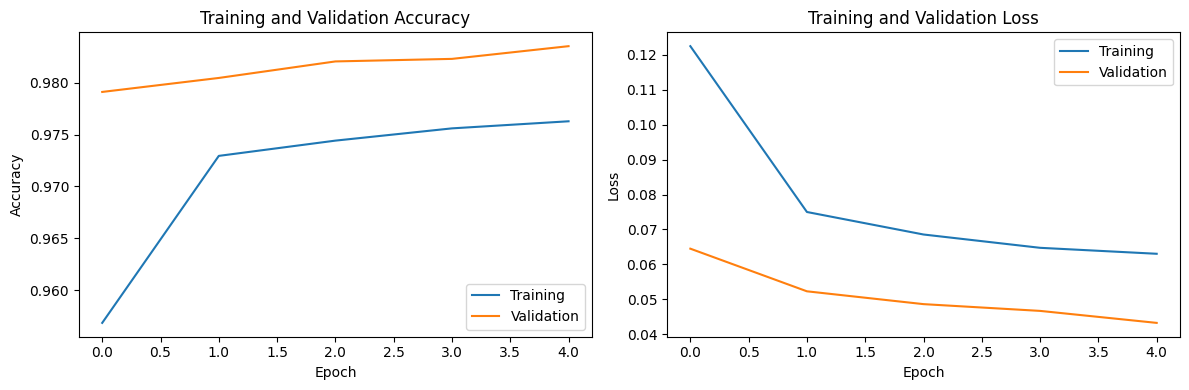


Classification Report:
              precision    recall  f1-score   support

     Healthy       0.98      0.98      0.98      2286
    Diseased       0.99      0.99      0.99      5859

    accuracy                           0.99      8145
   macro avg       0.98      0.98      0.98      8145
weighted avg       0.99      0.99      0.99      8145



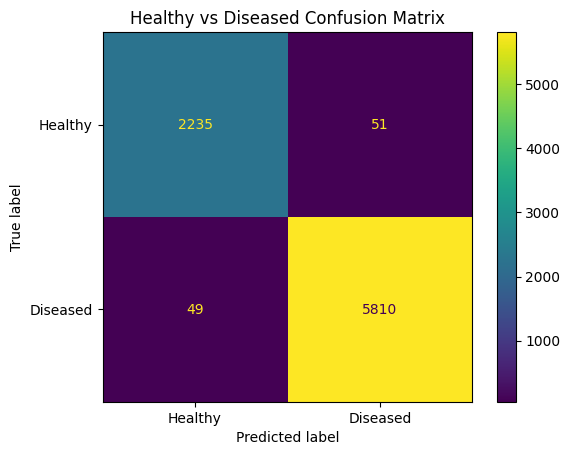

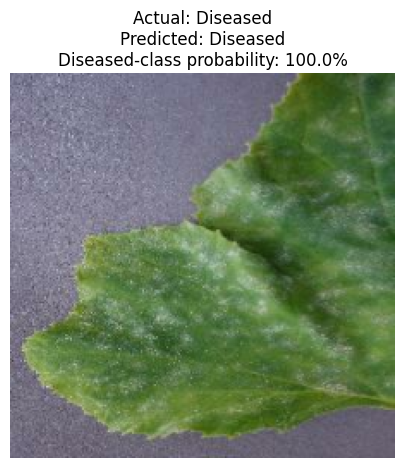


Model saved to:
/content/crop_leaf_binary_classifier.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


PROJECT TRAINING COMPLETE!


In [4]:

# ============================================================
# CROP LEAF DISEASE CLASSIFICATION
# Healthy vs Diseased using EfficientNetB0
# Memory-efficient Google Colab version
# ============================================================

import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------ 1. SETTINGS ------------------

IMG_SIZE = 224
BATCH_SIZE = 8       # Lower memory usage
EPOCHS = 5
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Loading PlantVillage dataset...")

# ------------------ 2. LOAD DATA ------------------
# Images are streamed rather than stored in one large NumPy array.

(train_raw, val_raw, test_raw), info = tfds.load(
    "plant_village",
    split=[
        "train[:70%]",
        "train[70%:85%]",
        "train[85%:]"
    ],
    as_supervised=True,
    with_info=True
)

class_names = info.features["label"].names

# Identify original classes containing the word "healthy".
healthy_ids = [
    i for i, name in enumerate(class_names)
    if "healthy" in name.lower()
]

print("Total original classes:", len(class_names))
print("Healthy class names:", [class_names[i] for i in healthy_ids])
print("Total images:", info.splits["train"].num_examples)

# Binary labels:
# 0 = Healthy
# 1 = Diseased

healthy_ids_tensor = tf.constant(healthy_ids, dtype=tf.int64)

# ------------------ 3. PREPROCESS DATA ------------------

def preprocess(image, original_label):
    # Resize one image at a time.
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)

    is_healthy = tf.reduce_any(
        tf.equal(original_label, healthy_ids_tensor)
    )

    binary_label = tf.where(is_healthy, 0, 1)
    binary_label = tf.cast(binary_label, tf.float32)

    return image, binary_label


def prepare_dataset(dataset, training=False):
    dataset = dataset.map(
        preprocess,
        num_parallel_calls=AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=512,
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(1)

    return dataset


train_ds = prepare_dataset(train_raw, training=True)
val_ds = prepare_dataset(val_raw)
test_ds = prepare_dataset(test_raw)

del train_raw, val_raw, test_raw

print("Datasets prepared!")

# ------------------ 4. BUILD MODEL ------------------

base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze pretrained layers for faster beginner-level training.
base_model.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.25)(x)

outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid"
)(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# ------------------ 5. TRAIN MODEL ------------------

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

# ------------------ 6. EVALUATE MODEL ------------------

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print("\nTest loss:", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy * 100, 2), "%")

# ------------------ 7. PLOT TRAINING RESULTS ------------------

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# ------------------ 8. CLASSIFICATION REPORT ------------------

y_true = []
y_prob = []

for images, labels in test_ds:
    probabilities = model.predict(images, verbose=0).reshape(-1)

    y_true.extend(labels.numpy().astype(int).tolist())
    y_prob.extend(probabilities.tolist())

y_true = np.array(y_true)
y_prob = np.array(y_prob)
y_pred = (y_prob >= 0.5).astype(int)

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Healthy", "Diseased"],
        zero_division=0
    )
)

# ------------------ 9. CONFUSION MATRIX ------------------

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy", "Diseased"]
)

disp.plot(values_format="d")
plt.title("Healthy vs Diseased Confusion Matrix")
plt.show()

# ------------------ 10. SAMPLE PREDICTION ------------------

for images, labels in test_ds.take(1):
    sample_image = images[0]
    actual_label = int(labels[0].numpy())

    probability = float(
        model.predict(
            tf.expand_dims(sample_image, axis=0),
            verbose=0
        )[0][0]
    )

    predicted_label = int(probability >= 0.5)

    plt.figure(figsize=(5, 5))
    plt.imshow(tf.cast(sample_image, tf.uint8))
    plt.axis("off")

    plt.title(
        f"Actual: {['Healthy', 'Diseased'][actual_label]}\n"
        f"Predicted: {['Healthy', 'Diseased'][predicted_label]}\n"
        f"Diseased-class probability: {probability:.1%}"
    )

    plt.show()
    break

# ------------------ 11. SAVE MODEL ------------------

model.save("/content/crop_leaf_binary_classifier.keras")

print("\nModel saved to:")
print("/content/crop_leaf_binary_classifier.keras")

# Download the trained model to your computer.
from google.colab import files
files.download("/content/crop_leaf_binary_classifier.keras")

print("\nPROJECT TRAINING COMPLETE!")
